# 实验报告 02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

姓名：欧阳洋　　学号：20244080124

本报告对应四个实验的 22 项操作任务，包含代码、实际输出与关键结果分析。

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import pandas as pd

STUDENT_ID = 20244080124
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")
print(f"[Python 版本] {platform.python_version()}")
print(f"[库版本] NumPy={np.__version__}, SciPy={scipy.__version__}, Matplotlib={matplotlib.__version__}, pandas={pd.__version__}")


[Conda 环境] python_work1
[学号]       20244080124
[机器指纹] 66ab728912afd30e
[RUN_ID]   20244080124-66ab728912afd30e
[Python 版本] 3.12.15
[库版本] NumPy=2.5.4, SciPy=1.18.1, Matplotlib=3.11.2, pandas=3.0.6


## 实验环境与目的

使用独立 Conda 环境 `python_work1` 和 `Python (python_work1)` 内核。首个代码单元实际读取环境、学号、
机器指纹和依赖版本。重启内核后从上到下运行，避免依赖其他 Notebook 的变量。

实验目标是理解数组与矩阵操作、随机抽样和缺失值、数值求解与可视化，以及表格的筛选和分组统计。
涉及抽样的代码显式使用固定种子：成绩与抽样使用本人学号，t 检验使用本人学号加 1。
同版本、同种子和相同调用顺序下结果可复现。表格与 CSV 均在内存中处理，三幅图直接显示于 Notebook。

## 实验 1：NumPy 数组、数据类型与索引

### 1.1 数组类型、形状和维数

创建整数、浮点数和布尔数组，并逐一输出内容、dtype、shape 和 ndim。

In [2]:
#1.1
a = np.array([1, 2, 3])
b = np.array([1.2, 2.5, 3.8])
c = np.array([True, False, True])

for x in [a, b, c]:
    print(x)
    print("dtype:", x.dtype, "shape:", x.shape, "ndim:", x.ndim)
    # 1.1、 NumPy 数组的数据类型与 Python 列表的差别?
    # NumPy数组里的元素一般是同一种类型
    # 而 Python 列表可以同时放不同类型的数据


[1 2 3]
dtype: int64 shape: (3,) ndim: 1
[1.2 2.5 3.8]
dtype: float64 shape: (3,) ndim: 1
[ True False  True]
dtype: bool shape: (3,) ndim: 1


**结果分析：** 三个数组的 shape 都是 `(3,)`，ndim 都是 1，dtype 分别为整数、浮点数和布尔类型。普通数值 ndarray 用一个 dtype 描述元素存储类型，构造混合数值数组时通常会发生统一类型转换；Python 列表可以同时保存不同类型的对象。NumPy 也允许 object 数组，因此“数组只能存一种 Python 对象”并不准确。

### 1.2 reshape 与元素总数

把 12 个元素分别整理为二维和三维数组。

In [3]:
# 1.2
arr = np.arange(12)
arr1 = arr.reshape(3, 4)
arr2 = arr.reshape(2, 3, 2)
print(arr)
print(arr1)
print(arr2)
#1.2、说明改变形状时元素总数必须满⾜什么条件？ 改变形状前后元素个数不能变


[ 0  1  2  3  4  5  6  7  8  9 10 11]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


**结果分析：** `3×4=12`，`2×3×2=12`，因此两种形状都可用。改变形状前后元素总数必须相同，元素的先后次序在本例中按默认 C 顺序保留；reshape 不会新增或丢弃数据。

### 1.3 行、列和布尔索引

第 2 行对应下标 1，第 1 至第 3 列使用左闭右开的切片 `:3`。

In [4]:
#1.3
row2 = arr1[1, :]
col1_3 = arr1[:, :3]
greater6 = arr1[arr1 > 6]

print("第2行：", row2, "形状：", row2.shape)
print("第1~3列：\n", col1_3, "形状：", col1_3.shape)
print("大于6：", greater6, "形状：", greater6.shape)


第2行： [4 5 6 7] 形状： (4,)
第1~3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状： (3, 3)
大于6： [ 7  8  9 10 11] 形状： (5,)


**结果分析：** 第 2 行为 `[4, 5, 6, 7]`，shape 为 `(4,)`；前三列的 shape 为 `(3, 3)`；大于 6 的元素为 `[7, 8, 9, 10, 11]`，shape 为 `(5,)`。布尔筛选按顺序提取匹配元素，结果是一维数组。

### 1.4 复合条件筛选

每个比较条件加括号，使用逐元素逻辑运算符 `|` 和 `&`，避免使用 Python 标量的 and/or。

In [5]:
#1.4
n = np.arange(10)
print(n[(n < 2) | (n > 7)])
print(n[(n > 3) & (n < 7)])


[0 1 8 9]
[4 5 6]


**结果分析：** “小于 2 或大于 7”得到 `[0, 1, 8, 9]`；“大于 3 且小于 7”得到 `[4, 5, 6]`。括号使比较先生成布尔数组，再进行逐元素逻辑组合。

### 1.5 逐元素乘法与矩阵乘法

使用同一对 2×2 数组比较四种写法。

In [6]:
#1.5
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])
print("*：", m1 * m2)
print("multiply：", np.multiply(m1, m2))
print("@ ：", m1 @ m2)
print("matmul：", np.matmul(m1, m2))
#1.5、说明逐元素乘法与矩阵乘法的区别？
# `*` 和 `multiply` 是对应位置相乘，
# `@` 和 `matmul` 是按矩阵乘法规则计算。


*： [[ 5 12]
 [21 32]]
multiply： [[ 5 12]
 [21 32]]
@ ： [[19 22]
 [43 50]]
matmul： [[19 22]
 [43 50]]


**结果分析：** `*` 与 `np.multiply()` 都给出 `[[5, 12], [21, 32]]`，是对应位置相乘；`@` 与 `np.matmul()` 都给出 `[[19, 22], [43, 50]]`，按“行乘列并求和”计算。例如矩阵乘法左上角为 `1×5 + 2×7 = 19`，不能与逐元素的 `1×5 = 5` 混淆。

## 实验 2：随机抽样、统计与缺失值

### 2.1 固定种子生成模拟成绩

生成 1,000 个均值参数为 70、标准差参数为 10 的正态样本，再裁剪到 [0, 100]。

In [7]:
#2.1
# default_rng中传入固定的种子，这样重新运行时得到的随机数相同
rng = np.random.default_rng(STUDENT_ID)
scores = rng.normal(70, 10, 1000)
# clip把小于0的值改成0，大于100的值改成100
scores = np.clip(scores, 0, 100)

print("样本数：", len(scores))
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std(ddof=0))
print("极差：", np.ptp(scores))


样本数： 1000
最小值： 39.07382373191003
最大值： 96.95649589286317
均值： 69.84619837465061
标准差： 10.032329356385468
极差： 57.88267216095314


**结果分析：** 样本数为 1,000，裁剪后所有成绩位于 [0, 100]。均值和标准差是实际样本统计量，不必恰为 70 和 10。`std(ddof=0)` 使用 n 作分母；极差等于最大值减最小值。clip 将越界值压到端点，因此裁剪后的分布不再严格等同于原正态分布。

本次固定种子的实际结果：均值 **69.846198**，标准差 **10.032329**，最小值 **39.073824**，最大值 **96.956496**，极差 **57.882672**。

### 2.2 两种不放回抽样

从 1～10 中各抽取 5 个数；加权抽样把整数大小归一化作为权重。

In [8]:
# 2.2
numbers = np.arange(1, 11)
# replace=False表示抽到的数不会再放回去
normal_choice = rng.choice(numbers, 5, replace=False)
# 每个数除以总和后就得到对应的抽样概率，数越大概率越大
p = numbers / numbers.sum()
weighted_choice = rng.choice(numbers, 5, replace=False, p=p)
print("均匀抽样：", normal_choice)
print("加权抽样：", weighted_choice)


均匀抽样： [ 2  1 10  4  3]
加权抽样： [ 3  7  9 10  6]


**结果分析：** 两种写法都指定 `replace=False`，各自的 5 个结果不会重复。均匀抽样不设置 p；加权抽样使用 `p_i=i/55`，且权重总和为 1。无放回抽样过程中剩余权重会重新归一化，不能把初始 p 直接当作“最终入选 5 个数”的包含概率，也不能凭单次结果断言较大数必然入选。

### 2.3 随机排列和原地打乱

分别打印操作前后的原数组，区分返回新排列和修改原数组。

In [9]:
#2.3
x = np.arange(1, 11)
print("原数组：", x)
y = rng.permutation(x)
print("permutation结果：", y)
print("原数组仍为：", x)

z = np.arange(1, 11)
print("shuffle前：", z)
rng.shuffle(z)
print("shuffle后：", z)
# 2.3、两种随机排列有什么区别？
# permutation产生一个新的数组，所以x没有改变
# shuffle是在原数组上操作，所以z本身被打乱了


原数组： [ 1  2  3  4  5  6  7  8  9 10]
permutation结果： [ 1  9 10  3  2  6  8  4  7  5]
原数组仍为： [ 1  2  3  4  5  6  7  8  9 10]
shuffle前： [ 1  2  3  4  5  6  7  8  9 10]
shuffle后： [ 9  3  5  8  4  7  1 10  2  6]


**结果分析：** `permutation(x)` 返回新数组，原来的 x 保持 1～10；`shuffle(z)` 直接改变 z 的排列，返回值是 None。两种操作都只改变顺序，不改变元素集合。固定种子并保持调用顺序，排列结果即可复现。

### 2.4～2.5 缺失值与内存表格

第 10、20、30 个位置对应从 0 开始的下标 9、19、29；复制原成绩后再设置 NaN。

In [10]:
# 2.4
scores_nan = scores.copy()
# 第10、20、30个值的下标分别是9、19、29
scores_nan[[9, 19, 29]] = np.nan
print("普通均值：", np.mean(scores_nan))
print("忽略缺失值的均值：", np.nanmean(scores_nan))
print("缺失值个数：", np.isnan(scores_nan).sum())
# 2.4、nan对普通统计函数有什么影响？
# mean遇到nan后结果也是nan，nanmean会先跳过缺失值再计算

#2.5
# DataFrame只保存在变量中，没有写入磁盘，后面实验4可以继续使用
score_df = pd.DataFrame({
    "序号": np.arange(1, 1001),
    "成绩": scores_nan
})
score_df.head(12)


普通均值： nan
忽略缺失值的均值： 69.85902591325679
缺失值个数： 3


,序号,成绩
0,1,66.962453
1,2,64.649425
2,3,80.338653
3,4,77.598889
4,5,79.530544
5,6,53.257518
6,7,76.270157
7,8,60.340799
8,9,55.263318
9,10,NaN


**结果分析：** 普通均值为 NaN，`nanmean()` 跳过 3 个缺失值，用 997 个有效值计算均值。NaN 会传播到普通 mean、min 等统计结果，不能把缺失成绩当作 0。score_df 包含 1,000 行、序号和成绩两列，仅保存在内存中，后续实验直接复用。

本次忽略缺失值后的均值为 **69.859026**，而普通均值为 NaN。

## 实验 3：SciPy 数值计算与 Matplotlib 可视化

### 3.1 解线性方程组

将方程组写为 A·x=b，求解后用 NumPy 矩阵乘法代入。

In [11]:
#3.1
from scipy import linalg, optimize, stats

# 把方程组左边的系数写成矩阵A，右边写成b
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
answer = linalg.solve(A, b)
print("方程组的解：", answer)
print("代入结果：", A @ answer)
# allclose适合判断浮点数计算结果是否近似相等
print("验证：", np.allclose(A @ answer, b))


方程组的解： [2. 3.]
代入结果： [9. 8.]
验证： True


**结果分析：** 解为 `(x, y)=(2, 3)`，代入得到 `[9, 8]`，与右端项一致。`np.allclose()` 在浮点容差内核对结果，避免直接比较浮点数造成误判。

### 3.2 正根、负根与残差

分别从初值 1 和 -1 出发求解 x²−2=0，并显示成功标志和代入后的函数值。

In [12]:
# 3.2
def fun(x):
    return x ** 2 - 2

# 初始值1靠近正根，-1靠近负根
r1 = optimize.root(fun, 1)
r2 = optimize.root(fun, -1)
print("正根是否成功：", r1.success, "正根：", r1.x[0], "函数值：", fun(r1.x[0]))
print("负根是否成功：", r2.success, "负根：", r2.x[0], "函数值：", fun(r2.x[0]))
# 两个函数值都非常接近0，说明求出的结果确实是方程的根


正根是否成功： True 正根： 1.4142135623730947 函数值： -8.881784197001252e-16
负根是否成功： True 负根： -1.4142135623730947 函数值： -8.881784197001252e-16


**结果分析：** 两个解应分别接近 `√2≈1.414214` 和 `−√2≈−1.414214`，函数值接近 0。正负初值分别引导到对应根；成功标志和残差应一起检查，仅打印一个数值不足以确认求根成功。

### 3.3 二次函数最小值与解析比较

从 x=0 开始最小化 x²+x+2，检查求解状态并比较误差。

In [13]:
#3.3
def f(x):
    return x[0] ** 2 + x[0] + 2

result = optimize.minimize(f, [0])
print("极小点：", result.x[0])
print("最小值：", result.fun)
print("解析结果：x=-0.5，f(x)=1.75")
# 3.3、与解析结果比较
# 数值结果和解析结果很接近，出现很小的误差是浮点数计算造成的
print("优化是否成功：", result.success)
print("极小点绝对误差：", abs(result.x[0] - (-0.5)))
print("最小值绝对误差：", abs(result.fun - 1.75))


极小点： -0.5000000064345924
最小值： 1.75
解析结果：x=-0.5，f(x)=1.75
优化是否成功： True
极小点绝对误差： 6.434592414450435e-09
最小值绝对误差： 0.0


**结果分析：** 由 `f′(x)=2x+1=0` 得 `x=−0.5`；`f″(x)=2>0`，因此它是全局极小点，最小值为 `1.75`。数值解应与解析值在小容差内一致。微小偏差来自浮点表示、有限精度和优化算法的终止容差。

### 3.4 独立样本双侧 t 检验

各生成 100 个独立观测，分布参数为 N(0,1) 和 N(1,1)，固定种子为本人学号加 1。原假设是两个总体均值相等，显著性水平 α=0.05。

In [14]:
# 3.4
rng2 = np.random.default_rng(STUDENT_ID + 1)
sample1 = rng2.normal(0, 1, 100)
sample2 = rng2.normal(1, 1, 100)
# ttest_ind用来检验两个独立样本的均值是否有明显差异
t, p_value = stats.ttest_ind(sample1, sample2, equal_var=True, alternative="two-sided")
print("第一组均值：", sample1.mean(), "第二组均值：", sample2.mean())
print("t统计量：", t)
print("p值：", p_value)
if p_value < 0.05:
    print("p<0.05，拒绝原假设，两组均值有显著差异")
else:
    print("p>=0.05，不能拒绝原假设")
# 判断时把p值和题目给出的显著性水平0.05比较


第一组均值： 0.1626710042185708 第二组均值： 0.9163909473158743
t统计量： -5.132412648386602
p值： 6.806693559715757e-07
p<0.05，拒绝原假设，两组均值有显著差异


**结果分析：** 两组模拟总体的标准差参数都为 1，因此这里明确使用等方差、双侧独立样本 t 检验。t 的正负对应“第一组减第二组”的方向；根据实际输出将 p 与 0.05 比较。p<0.05 时拒绝均值相等的原假设；p≥0.05 时只能说证据不足以拒绝，不能据此证明均值相同。p 值不是“原假设为真的概率”。

本次实际结果：**t=-5.132413，p=6.806694e-07**；p 小于 0.05，因此在 5% 显著性水平下拒绝两个总体均值相等的原假设。这一结论针对本次独立模拟样本，不意味着两组中每个观测值都存在固定差值。

### 3.5 有效成绩与三条函数曲线

使用 997 个有效成绩分别作直方图和箱线图，并在 0≤x≤5 的同一坐标系中画 y=x、y=x²、y=x³。每张图包含标题和双轴标签，函数曲线包含图例；仅在 Notebook 中显示。

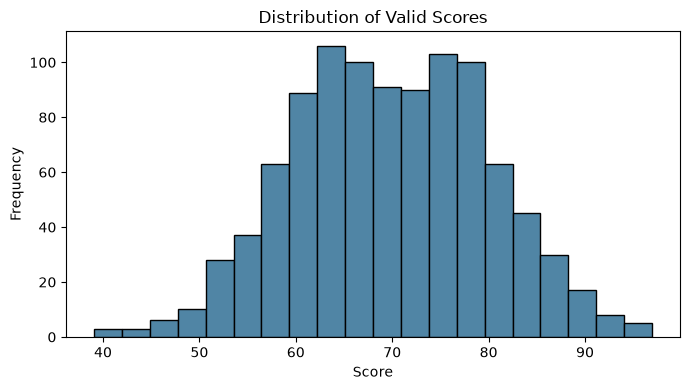

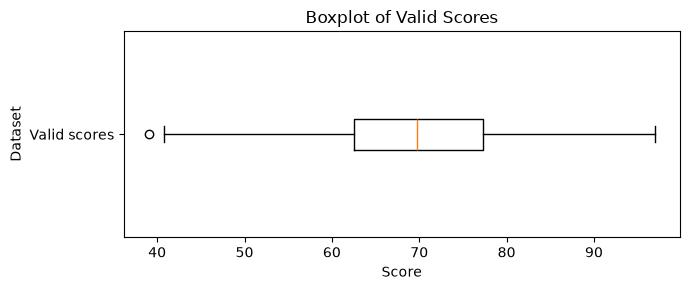

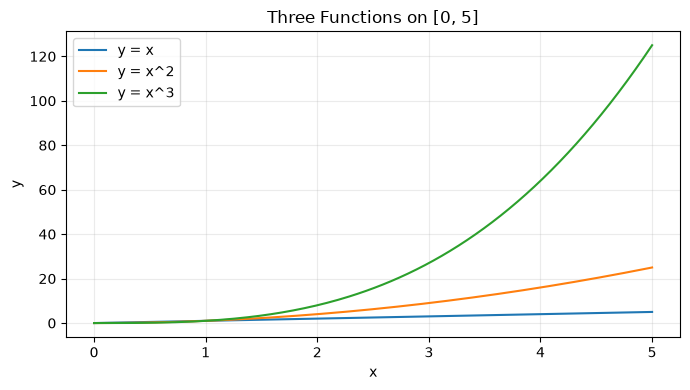

In [15]:
valid_scores = score_df["成绩"].dropna()

hist_fig, hist_ax = plt.subplots(figsize=(7, 4))
hist_ax.hist(valid_scores, bins=20, edgecolor="black", color="#5085a5")
hist_ax.set(title="Distribution of Valid Scores", xlabel="Score", ylabel="Frequency")
hist_fig.tight_layout()
plt.show()

box_fig, box_ax = plt.subplots(figsize=(7, 3))
box_ax.boxplot(valid_scores, orientation="horizontal", tick_labels=["Valid scores"])
box_ax.set(title="Boxplot of Valid Scores", xlabel="Score", ylabel="Dataset")
box_fig.tight_layout()
plt.show()

x = np.linspace(0, 5, 200)
line_fig, line_ax = plt.subplots(figsize=(7, 4))
line_ax.plot(x, x, label="y = x")
line_ax.plot(x, x ** 2, label="y = x^2")
line_ax.plot(x, x ** 3, label="y = x^3")
line_ax.set(title="Three Functions on [0, 5]", xlabel="x", ylabel="y")
line_ax.legend()
line_ax.grid(alpha=0.25)
line_fig.tight_layout()
plt.show()
figures_02 = [hist_fig, box_fig, line_fig]


**结果分析：** 直方图展示频数分布，箱线图展示中位数、四分位数、须和离群点；图中的离群点不自动等于错误数据。三个函数都通过 `(0,0)` 和 `(1,1)`，在 `0<x<1` 时 `x³<x²<x`，在 `x>1` 时顺序相反，所以不能笼统说立方曲线在整个区间都最高。横轴 0～5 和曲线图例用于辨认对应关系。

## 实验 4：pandas Series、DataFrame 与内存中的 CSV 读写

### 4.1 表格、索引与描述统计

直接查看实验 2 的 score_df，再用题目指定 records 创建另一张六人成绩表。仅用 Math、English、Python 三科计算总分和均分，避免包含衍生列。

In [16]:
#4.1
# 实验2中建立的表格直接保存在内存中
print(score_df.head())

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82]
}

# set_index把Name列变成行索引，后面可以直接用姓名查找
df = pd.DataFrame(records).set_index("Name")
subjects = ["Math", "English", "Python"]
df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1)
print("行索引：", df.index)
print("列名：", df.columns)
print(df.head(3))
# describe可以一次看到数量、均值、标准差、最大最小值等信息
print(df.describe())


   序号         成绩
0   1  66.962453
1   2  64.649425
2   3  80.338653
3   4  77.598889
4   5  79.530544
行索引： Index(['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank'], dtype='str', name='Name')
列名： Index(['Group', 'Math', 'English', 'Python', 'Total', 'Average'], dtype='str')
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000

**结果分析：** 姓名成为行索引，Group 保留为列。Alice 总分为 273、平均分为 91；Carol 总分为 265、平均分约为 88.333。`head(3)` 显示前三行，`describe()` 默认汇总数值列的计数、均值、样本标准差、分位数和极值。单独选出一列或一行时通常得到 Series，整张二维表则是 DataFrame。

### 4.2 标签、位置与行筛选

分别用姓名标签和从 0 开始的位置读取 Carol，筛选 Average≥80 的学生。

In [17]:
# 4.2
# loc按行索引的名字读取，iloc按行的位置读取，Carol位于第3行所以位置是2
print("loc读取Carol：")
print(df.loc["Carol"])
print("iloc读取Carol：")
print(df.iloc[2])
print("平均分不低于80：")
print(df[df["Average"] >= 80])


loc读取Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc读取Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于80：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


**结果分析：** `loc["Carol"]` 与 `iloc[2]` 指向同一条记录，但前者按标签、后者按位置。平均分达标者为 Alice、Carol、Eva、Frank。此处筛选的是个人平均分，与后面的整组过滤不同。

### 4.3 按列均值与按行均值

显式选中三科，分别沿 axis=0 与 axis=1 聚合。

In [18]:
#4.3
# axis=0是每一列向下计算，所以得到每科平均分
print("每科平均分：")
print(df[subjects].mean(axis=0))
# axis=1是每一行横向计算，所以得到每个学生的平均分
print("每名学生三科平均分：")
print(df[subjects].mean(axis=1))


每科平均分：
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
每名学生三科平均分：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


**结果分析：** `axis=0` 沿各行向下聚合，得到 Math≈79.8333、English≈80.8333、Python≈83.6667；`axis=1` 横向聚合三科，得到每名学生的平均分，与 Average 列对应。

### 4.4 apply、agg 与排名

逐行取最高分，一次计算各科 min/mean/max，并按 Python 分数降序排名。

In [19]:
# 4.4
# apply让max依次作用在每一行，得到每人的三科最高分
df["Highest"] = df[subjects].apply(max, axis=1)
print(df[["Highest"]])
# agg可以一次使用多个统计函数
print(df[subjects].agg(["min", "mean", "max"]))
# ascending=False表示分数越高，名次数字越小
df["Python排名"] = df["Python"].rank(ascending=False, method="average")
print(df[["Python", "Python排名"]])


       Highest
Name          
Alice       95
Bob         80
Carol       91
David       73
Eva         92
Frank       84
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
       Python  Python排名
Name                   
Alice      95       1.0
Bob        80       5.0
Carol      89       2.0
David      70       6.0
Eva        86       3.0
Frank      82       4.0


**结果分析：** `apply(max, axis=1)` 产生每人的最高分；`agg()` 把多种汇总结果组织成表。Python 排名前三为 Alice、Carol、Eva。`ascending=False` 使高分名次更靠前；若有并列，`method="average"` 采用平均名次，本数据恰好没有并列。

### 4.5 分组汇总与 transform

按 Group 统计人数和三科均值，再为原表每一行增加本组 Python 均值。

In [20]:
#4.5
grouped = df.groupby("Group")
print("每组人数：")
print(grouped.size())
print("每组三科平均分：")
print(grouped[subjects].mean())
# transform的结果和原表行数相同，因此可以直接作为新的一列加回去
df["组内Python平均分"] = grouped["Python"].transform("mean")
print(df[["Group", "Python", "组内Python平均分"]])


每组人数：
Group
A    3
B    3
dtype: int64
每组三科平均分：
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333
      Group  Python  组内Python平均分
Name                            
Alice     A      95    87.000000
Bob       A      80    87.000000
Carol     B      89    80.333333
David     B      70    80.333333
Eva       A      86    87.000000
Frank     B      82    80.333333


**结果分析：** A、B 组各 3 人，Python 均值分别为 87 和 80.3333。分组 mean() 只有两行；transform("mean") 返回与原表一样的六行，并将对应组的均值对齐到各学生，适合直接添加新列。

### 4.6 按整组条件过滤

使用 GroupBy.filter 保留 Python 平均分不低于 80 的完整小组。

In [21]:
# 4.6
# filter判断的是整个小组，满足条件时保留这个组里的所有学生
kept = grouped.filter(lambda x: x["Python"].mean() >= 80)
print("保留的组：", kept["Group"].unique())
print("保留的学生：", kept.index.tolist())
print(kept)


保留的组： <StringArray>
['A', 'B']
Length: 2, dtype: str
保留的学生： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
      Group  Math  English  Python  Total    Average  Highest  Python排名  \
Name                                                                      
Alice     A    88       90      95    273  91.000000       95       1.0   
Bob       A    72       68      80    220  73.333333       80       5.0   
Carol     B    91       85      89    265  88.333333       91       2.0   
David     B    65       73      70    208  69.333333       73       6.0   
Eva       A    79       92      86    257  85.666667       92       3.0   
Frank     B    84       77      82    243  81.000000       84       4.0   

       组内Python平均分  
Name                
Alice    87.000000  
Bob      87.000000  
Carol    80.333333  
David    80.333333  
Eva      87.000000  
Frank    80.333333  


**结果分析：** A 组均值 87，B 组均值约 80.333，均达到条件，因此保留 A、B 两组和全部六名学生。这并非代码漏筛：David 的个人 Python 分数为 70，但他所属 B 组整体达标，所以也被保留。

### 4.7 协方差与皮尔森相关

只对三科原始成绩计算协方差和相关系数，选择 Math 与 English 解释。

In [22]:
#4.7
cov_result = df[subjects].cov()
corr_result = df[subjects].corr()
print("协方差矩阵：")
print(cov_result)
print("相关系数矩阵：")
print(corr_result)
print("Math和English的协方差：", cov_result.loc["Math", "English"])
print("Math和English的相关系数：", corr_result.loc["Math", "English"])
# 4.7、协方差符号与相关系数大小表示什么？
# 协方差为正表示两科成绩大致同向变化，为负表示反向变化
# 相关系数绝对值越接近1，线性关系越明显；越接近0，线性关系越弱


协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
Math和English的协方差： 62.56666666666668
Math和English的相关系数： 0.6535293080615485


**结果分析：** Math 与 English 的样本协方差约为 `62.5667>0`，表示这六名学生两科成绩有同向变化倾向；皮尔森 r≈`0.653529`，表示本样本存在正的线性关联，但不是完全线性关系。协方差带有分数乘积的量纲，相关系数无量纲且位于 [−1,1]。相关不代表因果，也不能仅凭六个样本推广到所有学生。

### 4.8 章节补充：内存中的 CSV 往返

用 StringIO 直接序列化实验 2 的 score_df，再从同一个内存缓冲区读回。此项补足章节标题中的 CSV 读写内容。

In [23]:
from io import StringIO

csv_buffer = StringIO()
score_df.to_csv(csv_buffer, index=False)
csv_buffer.seek(0)
restored_score_df = pd.read_csv(csv_buffer)
print("内存 CSV 前三行：")
print(restored_score_df.head(3))
print("序号一致：", np.array_equal(score_df["序号"], restored_score_df["序号"]))
print("成绩一致（NaN 按对应位置比较）：", np.allclose(score_df["成绩"], restored_score_df["成绩"], equal_nan=True))
print("读回缺失值数：", restored_score_df["成绩"].isna().sum())


内存 CSV 前三行：
   序号         成绩
0   1  66.962453
1   2  64.649425
2   3  80.338653
序号一致： True
成绩一致（NaN 按对应位置比较）： True
读回缺失值数： 3


**结果分析：** `to_csv(index=False)` 不写额外的 DataFrame 行索引；`seek(0)` 把缓冲区读指针移回开头。读回后序号一致，成绩在浮点容差内一致，仍有 3 个缺失值。全过程没有创建 CSV 磁盘文件。

## 结果复核

以下检查核对题目给定条件、已知解析解、样例表格结果和图表标注。

In [24]:
assert CONDA_ENV not in ("base", "") and os.path.isdir(os.path.join(os.environ.get("CONDA_PREFIX", ""), "conda-meta"))
assert STUDENT_ID == 20244080124 and scores.shape == (1000,)
assert np.all((scores >= 0) & (scores <= 100))
assert np.array_equal(np.flatnonzero(np.isnan(scores_nan)), [9, 19, 29])
assert len(valid_scores) == 997 and score_df.shape == (1000, 2)
assert len(np.unique(normal_choice)) == len(np.unique(weighted_choice)) == 5
assert np.isclose(p.sum(), 1)
assert np.allclose(answer, [2, 3]) and np.allclose(A @ answer, b)
assert r1.success and r2.success and np.allclose([r1.x[0], r2.x[0]], [np.sqrt(2), -np.sqrt(2)])
assert np.allclose([fun(r1.x[0]), fun(r2.x[0])], 0, atol=1e-10)
assert result.success and np.isclose(result.x[0], -0.5, atol=1e-6) and np.isclose(result.fun, 1.75)
assert len(sample1) == len(sample2) == 100 and 0 <= p_value <= 1
assert df.loc["Carol"].equals(df.iloc[2])
assert set(df.index[df["Average"] >= 80]) == {"Alice", "Carol", "Eva", "Frank"}
assert np.allclose(grouped["Python"].mean(), [87, 241 / 3])
assert set(kept.index) == set(records["Name"])
assert np.isclose(cov_result.loc["Math", "English"], 62.56666666666667)
assert np.isclose(corr_result.loc["Math", "English"], 0.6535293080615485)
pd.testing.assert_frame_equal(score_df, restored_score_df, check_exact=False, rtol=1e-12, atol=1e-12)
for figure in figures_02:
    ax = figure.axes[0]
    assert ax.get_title() and ax.get_xlabel() and ax.get_ylabel()
assert len(line_ax.get_legend().get_texts()) == 3
print("复核通过：本人身份、独立 Conda 环境、22 项操作任务、内存数据与三幅图表标注。")


复核通过：本人身份、独立 Conda 环境、22 项操作任务、内存数据与三幅图表标注。


## 实验小结与提交

NumPy 的形状和广播规则决定数组操作的含义；固定种子解决随机结果的复现；NaN 处理直接影响统计的分母。
数值求解应同时查看状态、残差和解析结果；可视化须结合坐标轴和图例解读。
pandas 的按行筛选、整组过滤与 transform 返回形状不同，不能互相替代。

提交文件为本 Notebook：`20244080124_欧阳洋_exp02.ipynb`。
图像和执行输出已经内嵌；实验 2 的数据与 CSV 不依赖额外的磁盘文件。